Dependencies

In [1]:
import ultralytics
yes = ultralytics.checks()

Ultralytics 8.4.60  Python-3.12.5 torch-2.12.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
Setup complete  (12 CPUs, 31.3 GB RAM, 424.8/474.8 GB disk)


In [2]:
import torch
print(f"Cuda available: {torch.cuda.is_available()}")
print(f"GPU count: {torch.cuda.device_count()}")
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU found")

Cuda available: True
GPU count: 1
GPU name: NVIDIA GeForce RTX 4050 Laptop GPU


In [3]:
print(torch.__version__)
print(torch.version.cuda)

2.12.0+cu126
12.6


In [4]:
!nvidia-smi

Mon Oct  5 01:12:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 596.56                 Driver Version: 596.56         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   44C    P0             12W /  103W |       0MiB /   6141MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Import Dataset

In [5]:
from ultralytics import YOLO
from datetime import datetime
import os

now = datetime.now()
now_str = now.strftime("%Y-%m-%d %H_%M_%S")

DATASET_YAML = os.path.normpath(os.path.join('dataset', 'abcd.v11-dataset_2600-no_augmentation-rebalanced.yolo26', 'data.yaml'))
RESULT_PATH = os.path.normpath(os.path.join('models', now_str))
if not os.path.exists(RESULT_PATH):
    os.makedirs(RESULT_PATH)

RANDOM_SEED = 42

PROJECT_NAME = 'capstone'
MODEL_NAME = now_str + ' YOLO26n'

Train

In [6]:
model = YOLO("yolo26n.pt")

In [7]:
results = model.train(
    data=DATASET_YAML,
    epochs=300,
    imgsz=256,
    batch=32,
    device=0,
    project=PROJECT_NAME,   # Nama folder project untuk menyimpan hasil
    name=MODEL_NAME,   # Nama eksperimen
    seed=RANDOM_SEED,
    deterministic=True
)

Ultralytics 8.4.60  Python-3.12.5 torch-2.12.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\abcd.v11-dataset_2600-no_augmentation-rebalanced.yolo26\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=300, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=2026-10-05 01_12_35 YOLO26n, nbs=64, 

=== GRAFIK TRAINING (LOSS & mAP) ===


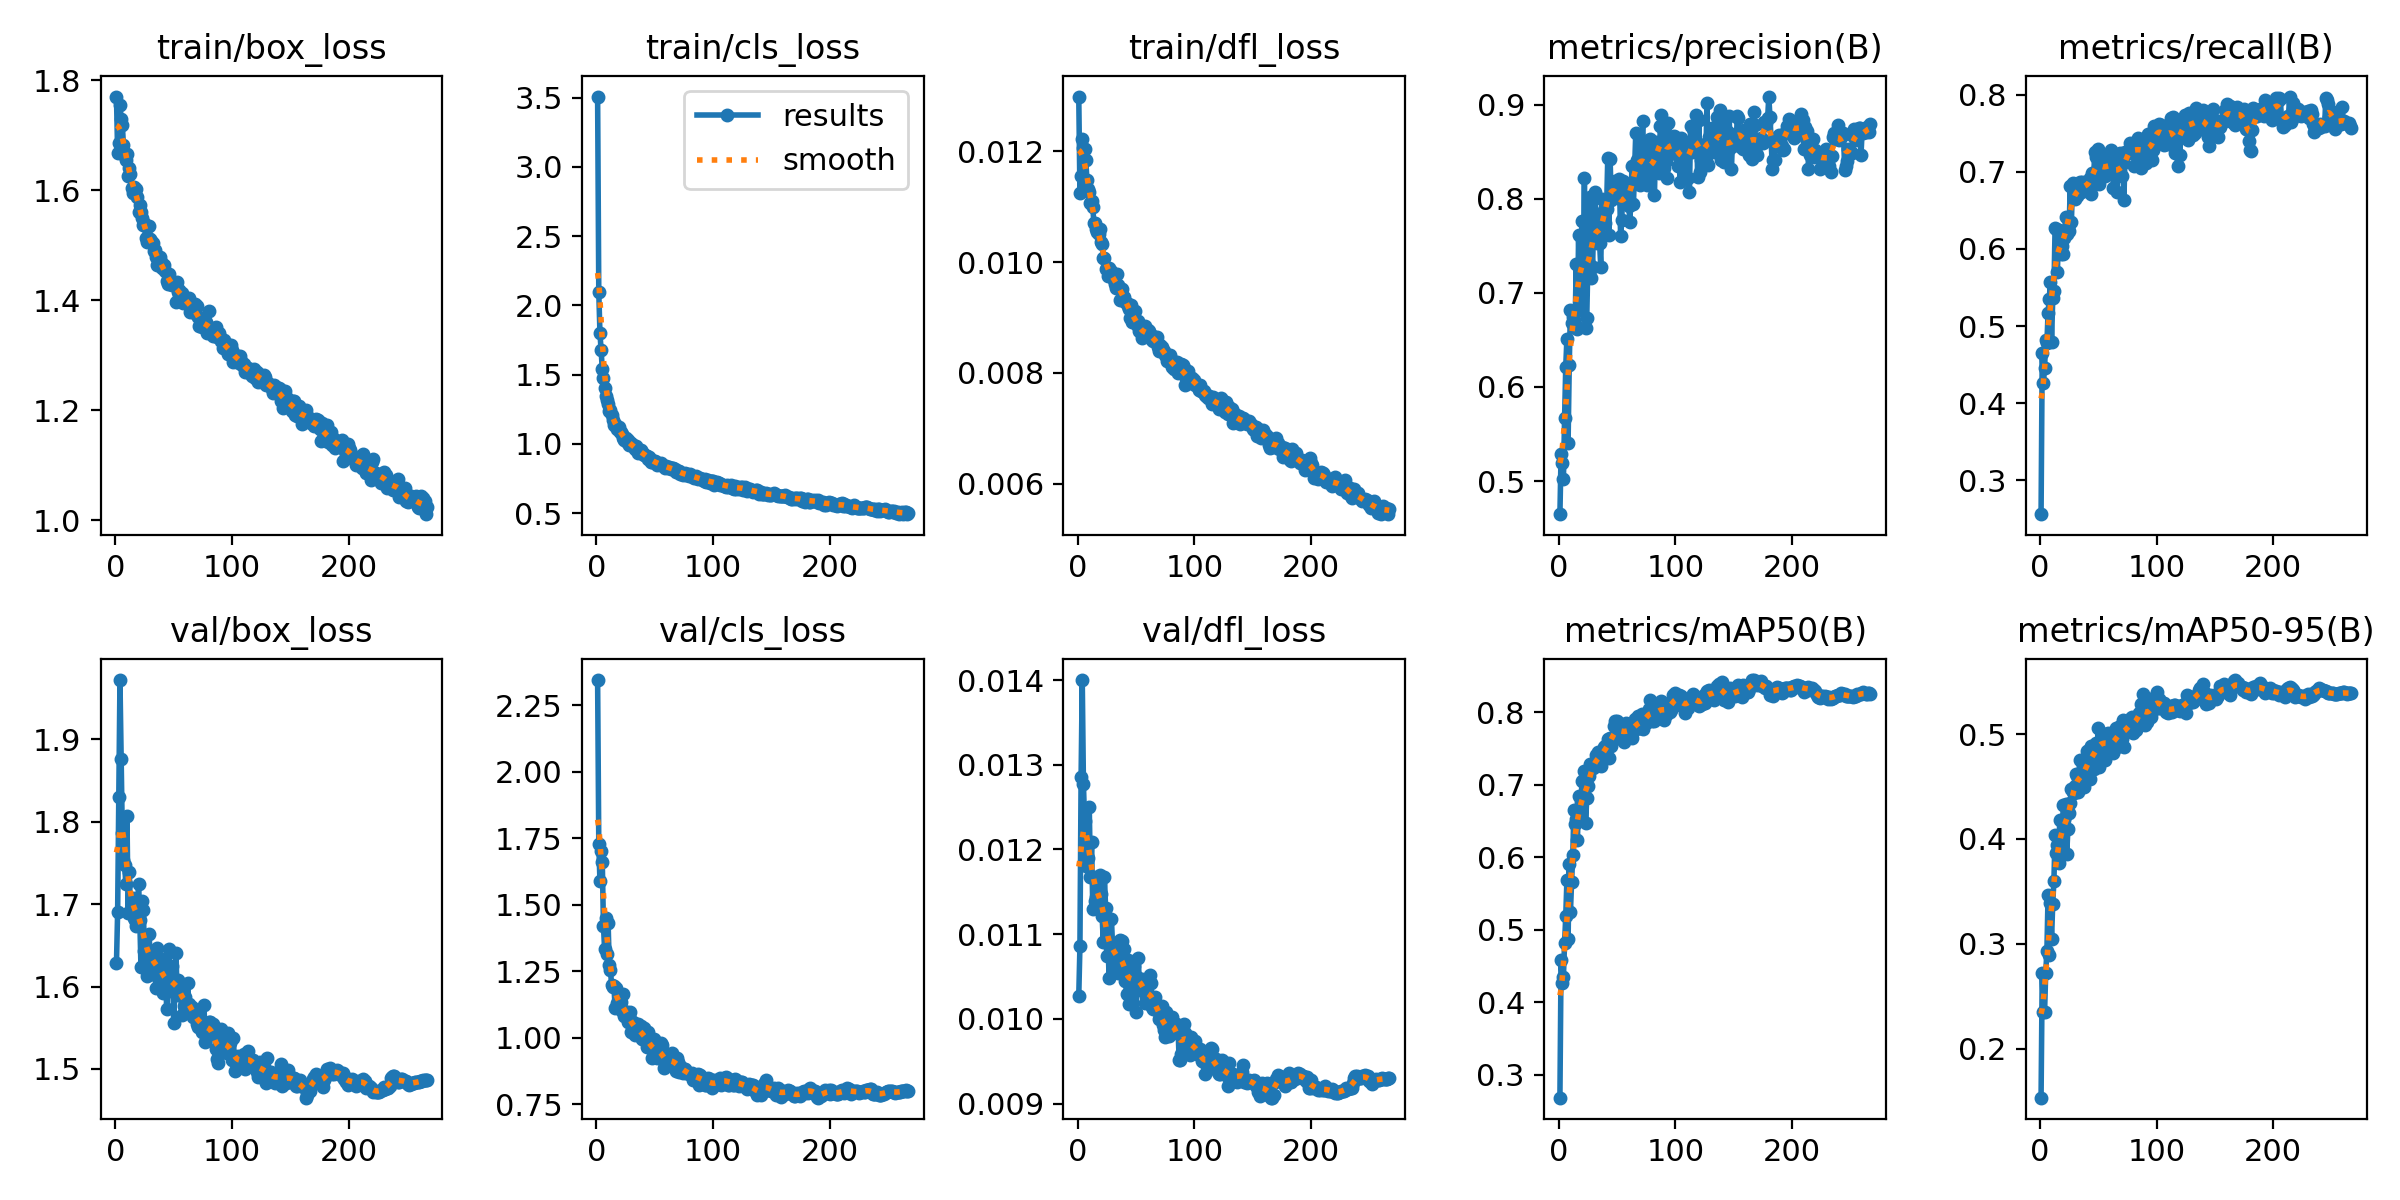


=== CONFUSION MATRIX (Evaluasi Per Kelas) ===


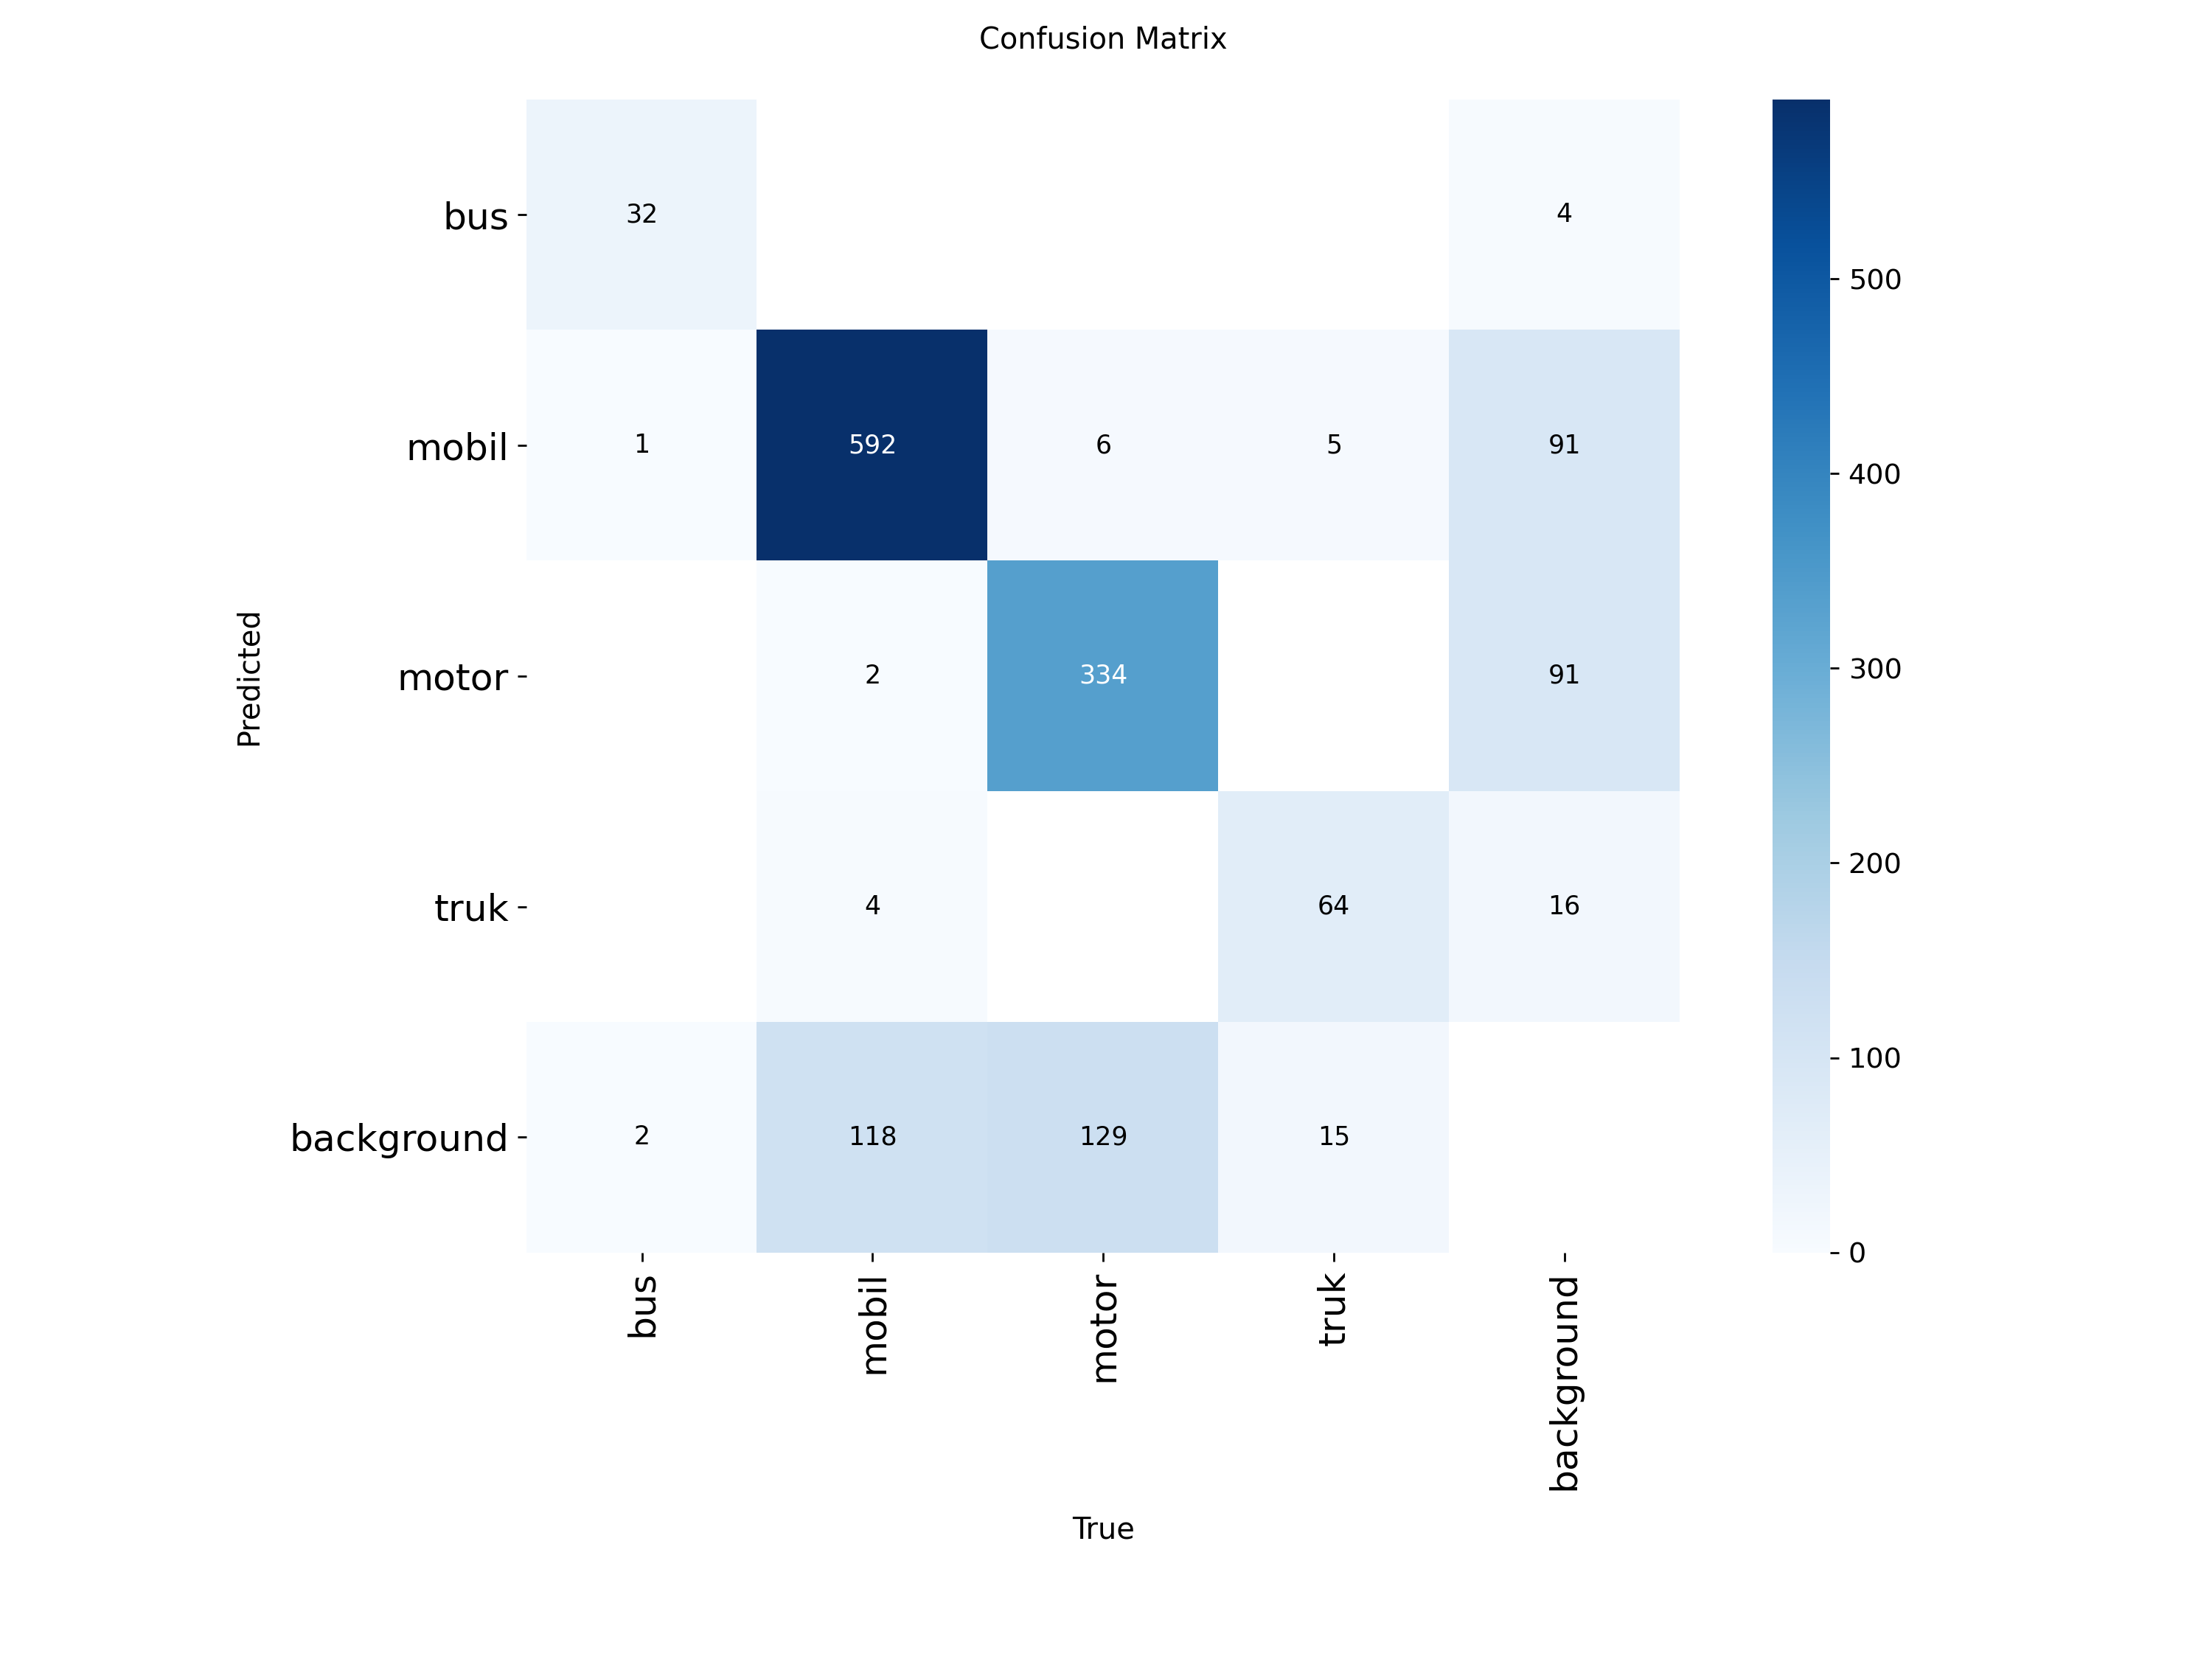


=== METRIK AKURASI TERBAIK (KESELURUHAN) ===
Ultralytics 8.4.60  Python-3.12.5 torch-2.12.0+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 142.960.3 MB/s, size: 10.9 KB)
val: Scanning D:\Kulyah\Capstone\detection\dataset\abcd.v11-dataset_2600-no_augmentation-rebalanced.yolo26\valid\labels.cache... 394 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 394/394  0.0s
WARNING Box and segment counts should be equal, but got len(segments) = 32, len(boxes) = 1304. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 17.3it/s 1.4s0.0s
                   all        394       1304      0.893       0.76      0.844      0.

In [8]:
from IPython.display import Image, display

print("=== GRAFIK TRAINING (LOSS & mAP) ===")
# Menampilkan grafik utama hasil training (Results.png)
display(Image(filename=f'runs/detect/{PROJECT_NAME}/{MODEL_NAME}/results.png', width=1000))

print("\n=== CONFUSION MATRIX (Evaluasi Per Kelas) ===")
display(Image(filename=f'runs/detect/{PROJECT_NAME}/{MODEL_NAME}/confusion_matrix.png', width=800))

print("\n=== METRIK AKURASI TERBAIK (KESELURUHAN) ===")
# Ambil metrik validasi dari model
metrics = model.val()

# 1. Metrik Keseluruhan (Overall)
mp = metrics.box.mp     # Mean Precision
mr = metrics.box.mr     # Mean Recall
map50 = metrics.box.map50 # mAP pada IoU 0.50
map95 = metrics.box.map   # mAP pada IoU 0.50:0.95

# Menghitung Overall F1-Score
f1_overall = 2 * (mp * mr) / (mp + mr + 1e-6)

print(f"Overall Precision : {mp:.4f} ({(mp*100):.1f}%)")
print(f"Overall Recall    : {mr:.4f} ({(mr*100):.1f}%)")
print(f"Overall F1-Score  : {f1_overall:.4f} ({(f1_overall*100):.1f}%)")
print(f"Overall mAP@50    : {map50:.4f} ({(map50*100):.1f}%)")


print("\n=== METRIK AKURASI PER KELAS ===")
# 2. Metrik Spesifik Per Kelas
class_indices = metrics.box.ap_class_index # Index kelas yang terdeteksi
class_names = model.names                  # Nama-nama kelas dari data.yaml
p_per_class = metrics.box.p                # Array Precision per kelas
r_per_class = metrics.box.r                # Array Recall per kelas
map50_per_class = metrics.box.ap50         # Array mAP@50 per kelas

# Loop untuk membedah akurasi masing-masing kelas
for i, c in enumerate(class_indices):
    name = class_names[c]
    p = p_per_class[i]
    r = r_per_class[i]
    ap50 = map50_per_class[i]
    
    # Menghitung F1-Score per kelas
    f1 = 2 * (p * r) / (p + r + 1e-6)
    
    print(f"Kelas [{name.upper()}]:")
    print(f"  - Precision : {(p*100):.1f}%")
    print(f"  - Recall    : {(r*100):.1f}%")
    print(f"  - F1-Score  : {(f1*100):.1f}%")
    print(f"  - mAP@50    : {(ap50*100):.1f}%\n")

Save the training & evaluation metrics

In [9]:
import shutil
import json
# from PIL import Image, ImageDraw, ImageFont
import os
import glob

# Copy generated graphs
graph_files = [
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxPR_curve.png',
    'BoxR_curve.png',
    'confusion_matrix_normalized.png',
    'labels.jpg',
    'results.jpg'
]

source_dir = os.path.normpath(os.path.join('runs', 'detect', PROJECT_NAME, MODEL_NAME))

for graph_file in graph_files:
    src = os.path.normpath(os.path.join(source_dir, graph_file))
    dst = os.path.join(RESULT_PATH, graph_file)
    if os.path.exists(src):
        shutil.copy(src, dst)
        continue

    matches = glob.glob(os.path.join(source_dir, '**', graph_file), recursive=True)
    if matches:
        shutil.copy(matches[0], dst)
    else:
        print(f"Warning: {src} not found")

# Save metrics to JSON
metrics_data = {
    'overall': {
        'precision': float(mp),
        'recall': float(mr),
        'f1_score': float(f1_overall),
        'map50': float(map50),
        'map95': float(map95)
    },
    'per_class': []
}

for i, c in enumerate(class_indices):
    name = class_names[c]
    p = float(p_per_class[i])
    r = float(r_per_class[i])
    ap50 = float(map50_per_class[i])
    f1 = 2 * (p * r) / (p + r + 1e-6)
    
    metrics_data['per_class'].append({
        'class_name': name,
        'precision': p,
        'recall': r,
        'f1_score': f1,
        'map50': ap50
    })

with open(os.path.join(RESULT_PATH, 'metrics.json'), 'w') as f:
    json.dump(metrics_data, f, indent=2)

print(f"All graphs copied and metrics saved to {RESULT_PATH}")

# # Save metrics as image

# # Create image for overall metrics
# img_width, img_height = 800, 400
# img = Image.new('RGB', (img_width, img_height), color='white')
# draw = ImageDraw.Draw(img)

# try:
#     font = ImageFont.truetype("arial.ttf", 20)
#     font_small = ImageFont.truetype("arial.ttf", 16)
# except:
#     font = ImageFont.load_default()
#     font_small = ImageFont.load_default()

# y_offset = 20
# draw.text((20, y_offset), "OVERALL METRICS", fill='black', font=font)
# y_offset += 40

# metrics_text = [
#     f"Precision: {mp:.4f} ({mp*100:.1f}%)",
#     f"Recall: {mr:.4f} ({mr*100:.1f}%)",
#     f"F1-Score: {f1_overall:.4f} ({f1_overall*100:.1f}%)",
#     f"mAP@50: {map50:.4f} ({map50*100:.1f}%)",
#     f"mAP@95: {map95:.4f} ({map95*100:.1f}%)"
# ]

# for text in metrics_text:
#     draw.text((20, y_offset), text, fill='black', font=font_small)
#     y_offset += 30

# img.save(os.path.join(RESULT_PATH, 'metrics_overall.png'))

# # Create image for per-class metrics
# img_height = 50 + len(class_indices) * 100
# img = Image.new('RGB', (img_width, img_height), color='white')
# draw = ImageDraw.Draw(img)

# y_offset = 20
# draw.text((20, y_offset), "PER-CLASS METRICS", fill='black', font=font)
# y_offset += 40

# for i, c in enumerate(class_indices):
#     name = class_names[c]
#     p = float(p_per_class[i])
#     r = float(r_per_class[i])
#     ap50 = float(map50_per_class[i])
#     f1 = 2 * (p * r) / (p + r + 1e-6)
    
#     draw.text((20, y_offset), f"[{name.upper()}]", fill='darkblue', font=font_small)
#     y_offset += 25
#     draw.text((30, y_offset), f"P: {p*100:.1f}% | R: {r*100:.1f}% | F1: {f1*100:.1f}% | mAP@50: {ap50*100:.1f}%", fill='black', font=font_small)
#     y_offset += 25

# img.save(os.path.join(RESULT_PATH, 'metrics_per_class.png'))

# print("Metrics saved as images: metrics_overall.png and metrics_per_class.png")

All graphs copied and metrics saved to models\2026-10-05 01_12_35


In [10]:
import os
import json
from PIL import Image, ImageDraw, ImageFont

# ── Color palette ──────────────────────────────────────────────────────────────
BG_COLOR        = (10,  12,  20)      # near-black background
CARD_COLOR      = (18,  22,  38)      # card surface
ACCENT_BLUE     = (30, 144, 255)      # overall-metrics bar fill  (#1E90FF)
ACCENT_BLUE_DIM = (18,  55, 100)      # overall bar track
TEXT_PRIMARY    = (235, 240, 255)
TEXT_SECONDARY  = (140, 155, 190)
LINE_COLOR      = (35,  42,  65)

CLASS_COLORS = {
    'bus':   (0,   255, 206),   # #00FFCE
    'mobil': (134,  34, 255),   # #8622FF
    'motor': (199, 252,   0),   # #C7FC00
    'truk':  (254,   0,  86),   # #FE0056
}

def dim_color(c, factor=0.25):
    """Return a darker version of color c for the bar track."""
    return tuple(max(0, int(v * factor)) for v in c)

# ── Font loader ────────────────────────────────────────────────────────────────
def load_fonts():
    candidates = [
        "F:\\fonts\\dejavu-sans\\DejaVuSans-Bold.ttf",
        "F:\\fonts\\dejavu-sans\\DejaVuSans.ttf",
        "F:\\fonts\\liberation_sans\\LiberationSans-Bold.ttf",
        "F:\\fonts\\liberation_sans\\LiberationSans-Regular.ttf",
        "arial.ttf",
    ]
    def try_load(size):
        for path in candidates:
            try:
                return ImageFont.truetype(path, size)
            except Exception:
                pass
        return ImageFont.load_default()

    return {
        'title':    try_load(26),
        'subtitle': try_load(18),
        'label':    try_load(14),
        'value':    try_load(14),
        'small':    try_load(12),
    }

FONTS = load_fonts()

# ── Drawing primitives ─────────────────────────────────────────────────────────
def draw_rounded_rect(draw, xy, radius, fill):
    x1, y1, x2, y2 = xy
    r = radius
    draw.rectangle([x1 + r, y1, x2 - r, y2], fill=fill)
    draw.rectangle([x1, y1 + r, x2, y2 - r], fill=fill)
    draw.ellipse([x1, y1, x1 + 2*r, y1 + 2*r], fill=fill)
    draw.ellipse([x2 - 2*r, y1, x2, y1 + 2*r], fill=fill)
    draw.ellipse([x1, y2 - 2*r, x1 + 2*r, y2], fill=fill)
    draw.ellipse([x2 - 2*r, y2 - 2*r, x2, y2], fill=fill)

def draw_bar(draw, x, y, width, height, pct, color_fill, color_track, radius=5):
    """Draw a full-width track + filled portion bar."""
    # track
    draw_rounded_rect(draw, (x, y, x + width, y + height), radius, color_track)
    # fill
    fill_w = max(int(width * pct), radius * 2 if pct > 0 else 0)
    if fill_w > 0:
        draw_rounded_rect(draw, (x, y, x + fill_w, y + height), radius, color_fill)

def text_width(draw, text, font):
    try:
        bbox = draw.textbbox((0, 0), text, font=font)
        return bbox[2] - bbox[0]
    except AttributeError:
        return draw.textsize(text, font=font)[0]

# ── Metric row (label + bar + value) ──────────────────────────────────────────
METRIC_LABELS = ['Precision', 'Recall', 'F1-Score', 'mAP@50']

def draw_metric_row(draw, x, y, bar_width, label, pct, color_fill, color_track):
    """Draw one metric row; returns height consumed."""
    lbl_w = 110
    val_w = 56
    gap   = 10
    bar_h = 10

    # label
    draw.text((x, y + 1), label, fill=TEXT_SECONDARY, font=FONTS['label'])
    # bar
    bx = x + lbl_w
    draw_bar(draw, bx, y + 3, bar_width, bar_h, pct, color_fill, color_track)
    # value
    val_str = f"{pct*100:.1f}%"
    vx = bx + bar_width + gap
    draw.text((vx, y + 1), val_str, fill=TEXT_PRIMARY, font=FONTS['value'])

    return 28   # row height

# ── Section card height estimator ─────────────────────────────────────────────
CARD_PAD_X = 24
CARD_PAD_Y = 18
ROW_H      = 28
OVERALL_INNER_H = CARD_PAD_Y + 22 + 12 + 5 * ROW_H + CARD_PAD_Y
SECTION_INNER_H = CARD_PAD_Y + 22 + 12 + 4 * ROW_H + CARD_PAD_Y

# ══════════════════════════════════════════════════════════════════════════════
# OVERALL METRICS IMAGE
# ══════════════════════════════════════════════════════════════════════════════
def save_overall_image(mp, mr, f1_overall, map50, map95, result_path):
    W = 720
    MARGIN = 32
    bar_width = W - 2*MARGIN - CARD_PAD_X*2 - 90 - 66   # lbl + val + gaps

    H = MARGIN + 40 + 16 + OVERALL_INNER_H + MARGIN

    img  = Image.new('RGB', (W, H), color=BG_COLOR)
    draw = ImageDraw.Draw(img)

    # ── header ──
    draw.text((MARGIN, MARGIN), "OVERALL METRICS", fill=TEXT_PRIMARY, font=FONTS['title'])
    draw.line([(MARGIN, MARGIN + 36), (W - MARGIN, MARGIN + 36)], fill=LINE_COLOR, width=1)

    # ── card ──
    cy = MARGIN + 36 + 16
    cx = MARGIN
    cw = W - 2*MARGIN
    ch = OVERALL_INNER_H
    draw_rounded_rect(draw, (cx, cy, cx + cw, cy + ch), 10, CARD_COLOR)

    # ── metrics inside card ──
    metrics = [
        ('Precision',  mp),
        ('Recall',     mr),
        ('F1-Score',   f1_overall),
        ('mAP@50',     map50),
        ('mAP@50-95',  map95),
    ]
    ry = cy + CARD_PAD_Y
    draw.text((cx + CARD_PAD_X, ry), f"Object Detection: {PROJECT_NAME}/{MODEL_NAME}", fill=TEXT_SECONDARY, font=FONTS['subtitle'])
    ry += 22 + 12

    for label, val in metrics:
        draw_metric_row(draw, cx + CARD_PAD_X, ry, bar_width,
                        label, val, ACCENT_BLUE, ACCENT_BLUE_DIM)
        ry += ROW_H

    img.save(os.path.join(result_path, 'metrics_overall.png'))
    print("Saved metrics_overall.png")


# ══════════════════════════════════════════════════════════════════════════════
# PER-CLASS METRICS IMAGE
# ══════════════════════════════════════════════════════════════════════════════
def save_per_class_image(class_indices, class_names,
                         p_per_class, r_per_class, map50_per_class,
                         result_path):
    W      = 720
    MARGIN = 32
    n_cls  = len(class_indices)

    bar_width = W - 2*MARGIN - CARD_PAD_X*2 - 90 - 66

    # two columns if ≥ 3 classes
    two_col = n_cls >= 3
    cols    = 2 if two_col else 1
    rows    = (n_cls + cols - 1) // cols

    COL_GAP  = 16
    card_w   = (W - 2*MARGIN - (cols - 1) * COL_GAP) // cols
    bar_width = card_w - CARD_PAD_X*2 - 90 - 66

    H = MARGIN + 40 + 16 + rows * (SECTION_INNER_H + 12) + MARGIN

    img  = Image.new('RGB', (W, H), color=BG_COLOR)
    draw = ImageDraw.Draw(img)

    # header
    draw.text((MARGIN, MARGIN), "PER-CLASS METRICS", fill=TEXT_PRIMARY, font=FONTS['title'])
    draw.line([(MARGIN, MARGIN + 36), (W - MARGIN, MARGIN + 36)], fill=LINE_COLOR, width=1)

    start_y = MARGIN + 36 + 16

    for idx, c in enumerate(class_indices):
        name  = class_names[c]
        p     = float(p_per_class[idx])
        r     = float(r_per_class[idx])
        ap50  = float(map50_per_class[idx])
        f1    = 2 * p * r / (p + r + 1e-6)

        color = CLASS_COLORS.get(name.lower(), ACCENT_BLUE)
        track = dim_color(color, 0.2)

        col_i = idx % cols
        row_i = idx // cols

        cx = MARGIN + col_i * (card_w + COL_GAP)
        cy = start_y + row_i * (SECTION_INNER_H + 12)

        draw_rounded_rect(draw, (cx, cy, cx + card_w, cy + SECTION_INNER_H), 10, CARD_COLOR)

        # colored left accent bar
        draw_rounded_rect(draw, (cx, cy, cx + 4, cy + SECTION_INNER_H), 2, color)

        # class name subtitle
        ry = cy + CARD_PAD_Y
        draw.text((cx + CARD_PAD_X, ry), name.upper(), fill=color, font=FONTS['subtitle'])
        ry += 22 + 12

        metrics = [
            ('Precision', p),
            ('Recall',    r),
            ('F1-Score',  f1),
            ('mAP@50',    ap50),
        ]
        for label, val in metrics:
            draw_metric_row(draw, cx + CARD_PAD_X, ry, bar_width,
                            label, val, color, track)
            ry += ROW_H

    img.save(os.path.join(result_path, 'metrics_per_class.png'))
    print("Saved metrics_per_class.png")


# ══════════════════════════════════════════════════════════════════════════════
# DROP-IN REPLACEMENT  — paste this block into your existing script
# ══════════════════════════════════════════════════════════════════════════════
def save_all_metric_images(mp, mr, f1_overall, map50, map95,
                           class_indices, class_names,
                           p_per_class, r_per_class, map50_per_class,
                           RESULT_PATH):
    """
    Call this function in place of the two PIL blocks in your original script.
    All other code (JSON saving, graph copying) is unchanged.
    """
    save_overall_image(mp, mr, f1_overall, map50, map95, RESULT_PATH)
    save_per_class_image(class_indices, class_names,
                         p_per_class, r_per_class, map50_per_class,
                         RESULT_PATH)
    print("Metrics saved as images: metrics_overall.png and metrics_per_class.png")

In [11]:
save_all_metric_images(mp, mr, f1_overall, map50, map95,
                       class_indices, class_names,
                       p_per_class, r_per_class, map50_per_class,
                       RESULT_PATH)

Saved metrics_overall.png
Saved metrics_per_class.png
Metrics saved as images: metrics_overall.png and metrics_per_class.png


Export

In [12]:
best_model_path = f'runs/detect/{PROJECT_NAME}/{MODEL_NAME}/weights/best.pt'
best_model = YOLO(best_model_path)

print("1. Sedang mengekspor ke format TFLite (INT8 Quantization)...")
tflite_path = best_model.export(
    format='tflite',
    imgsz=256,
    int8=True,            # Kuantisasi ekstrem menjadi 8-bit integer (sangat ringan)
    data=DATASET_YAML     # Path dataset untuk kalibrasi
)
print(f"TFLite INT8 berhasil disimpan di: {tflite_path}")

print("\n2. Sedang mengekspor ke format ONNX (FP16 Quantization)...")
# Export ke ONNX FP16
onnx_path = best_model.export(
    format='onnx',
    imgsz=256,
    half=True,            # Kuantisasi ke 16-bit float (mengecilkan ukuran 50% tapi akurasi nyaris sama)
    dynamic=False         # Kunci ke False agar input tetap statis 256x256 (Penting untuk kalkulasi koordinat IPM lu)
)
print(f"ONNX FP16 berhasil disimpan di: {onnx_path}")

# (Opsional) Salin hasilnya kembali ke Google Drive lu agar tidak hilang saat Colab ditutup
import shutil

# Ganti '/content/drive/MyDrive/' dengan path tujuan di drive lu
shutil.copy(best_model_path, RESULT_PATH)
shutil.copy(tflite_path, RESULT_PATH)
shutil.copy(onnx_path, RESULT_PATH)
print(f"\nSemua model hasil kuantisasi sudah di-backup ke {RESULT_PATH}!")

1. Sedang mengekspor ke format TFLite (INT8 Quantization)...
Ultralytics 8.4.60  Python-3.12.5 torch-2.12.0+cu126 CPU (AMD Ryzen 5 8645HS w/ Radeon 760M Graphics)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.2 GFLOPs

PyTorch: starting from 'runs\detect\capstone\2026-10-05 01_12_35 YOLO26n\weights\best.pt' with input shape (1, 3, 256, 256) BCHW and output shape(s) (1, 300, 6) (5.1 MB)
TensorFlow SavedModel: collecting INT8 calibration images from 'data=dataset\abcd.v11-dataset_2600-no_augmentation-rebalanced.yolo26\data.yaml'
val: Fast image access  (ping: 0.00.0 ms, read: 124.535.6 MB/s, size: 11.5 KB)
val: Scanning D:\Kulyah\Capstone\detection\dataset\abcd.v11-dataset_2600-no_augmentation-rebalanced.yolo26\valid\labels.cache... 394 images, 26 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 394/394  0.0s
WARNING Box and segment counts should be equal, but got len(segments) = 32, len(boxes) = 1304. To resolve this only boxes will be used and all segments will be 

d:\Kulyah\Capstone\detection\.venv\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset11.py:954: UserWarning: Exporting aten::index operator of advanced indexing in opset 20 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.
  return opset9.index(g, self, index)


ONNX: slimming with onnxslim 0.1.94...
ONNX: export success  1.6s, saved as 'runs\detect\capstone\2026-10-05 01_12_35 YOLO26n\weights\best.onnx' (9.2 MB)

TensorFlow SavedModel: starting export with tensorflow 2.19.1...

TensorFlow SavedModel: starting TFLite export with onnx2tf 1.28.8...
Saved artifact at 'runs\detect\capstone\2026-10-05 01_12_35 YOLO26n\weights\best_saved_model'. The following endpoints are available:

* Endpoint 'serving_default'
  inputs_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 256, 256, 3), dtype=tf.float32, name='images')
Output Type:
  TensorSpec(shape=(1, 300, 6), dtype=tf.float32, name=None)
Captures:
  1609053268560: TensorSpec(shape=(4, 2), dtype=tf.int32, name=None)
  1609053267792: TensorSpec(shape=(3, 3, 3, 16), dtype=tf.float32, name=None)
  1609053268176: TensorSpec(shape=(16,), dtype=tf.float32, name=None)
  1609071366736: TensorSpec(shape=(4, 2), dtype=tf.int32, name=None)
  1609053267216: TensorSpec(shape=(3, 3, 16, 32), dtype=tf.float32, name=None)